# 网格体检 / 流动参数

本 notebook 自包含（只读 `mesh.txt` 与 `parameters.json`），做三件事：

1. **流动参数**：给出 `Ma`、`Re`、静温 `T`、攻角 `AOA`，反算声速、来流速度、密度、静压、粘性、总温总压、动压
2. **网格合法性**：编号自洽、面-单元双向连通、四边形节点成环、单元不翻卷、边界闭合
3. **网格质量**：体积分布、正交性、长宽比、径向增长比、首层高度与 y+ 估算

公式与算法的正确性由 `tests/crosscheck.py` 对拍负责，不在本文件。

> 运行前需要 Jupyter 内核：`python -m pip install ipykernel`，然后 `python -m ipykernel install --user --name python3`。


In [ ]:
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'debug' else Path.cwd()
CASE = ROOT / 'cases' / 'cyc'
MESH = CASE / 'mesh.txt'

FLOW = dict(Ma=0.2, Re=1000.0, T=300.0, AOA_deg=0.0, D=1.0,
            gamma=1.4, R=287.05, Pr=0.71, mu0=1.716e-5, Ts=110.4, T0=273.15)

print('mesh :', MESH, f'{MESH.stat().st_size / 2**20:.1f} MiB')
print('case :', CASE)


## 1. 流动参数

`Ma`、`Re`、静温 `T`、攻角 `AOA`、参考长度 `D` 是输入，其余由气体关系式导出。
`p` 不作独立输入：低速风洞常用「给定 Re 反算密度」，这里沿用该约定。

$$a=\sqrt{\gamma RT},\quad U=Ma\,a,\quad \rho=\frac{Re\,\mu}{U D},\quad p=\rho RT$$


In [ ]:
g, R, Pr = FLOW['gamma'], FLOW['R'], FLOW['Pr']
Ma, Re, T, D = FLOW['Ma'], FLOW['Re'], FLOW['T'], FLOW['D']
alpha = math.radians(FLOW['AOA_deg'])

a = math.sqrt(g * R * T)
U = Ma * a
mu = FLOW['mu0'] * (T / FLOW['T0']) ** 1.5 * (FLOW['T0'] + FLOW['Ts']) / (T + FLOW['Ts'])
rho = Re * mu / (U * D)
p = rho * R * T
nu = mu / rho
q = 0.5 * rho * U * U
Tt = T * (1 + 0.5 * (g - 1) * Ma ** 2)
pt = p * (Tt / T) ** (g / (g - 1))
rhot = rho * (Tt / T) ** (1 / (g - 1))
Cp, Cv = g * R / (g - 1), R / (g - 1)
u, v = U * math.cos(alpha), U * math.sin(alpha)

ref = json.loads((CASE / 'parameters.json').read_text()) if (CASE / 'parameters.json').exists() else {}
rmap = {'Ma': ref.get('Ma'), 'T': ref.get('T_K'), 'U': ref.get('U_m_s'), 'rho': ref.get('rho_kg_m3'),
        'p': ref.get('p_Pa'), 'mu': ref.get('mu_Pa_s'), 'Re': ref.get('Re')}

rows = [
    ('绝热指数', 'gamma', g, '-', None),
    ('气体常数', 'R', R, 'J/(kg K)', None),
    ('定压比热', 'Cp', Cp, 'J/(kg K)', None),
    ('定容比热', 'Cv', Cv, 'J/(kg K)', None),
    ('普朗特数', 'Pr', Pr, '-', None),
    ('马赫数', 'Ma', Ma, '-', rmap['Ma']),
    ('静温', 'T', T, 'K', rmap['T']),
    ('声速', 'a', a, 'm/s', None),
    ('来流速度', 'U', U, 'm/s', rmap['U']),
    ('攻角', 'AOA', FLOW['AOA_deg'], 'deg', None),
    ('x 向速度', 'u', u, 'm/s', None),
    ('y 向速度', 'v', v, 'm/s', None),
    ('z 向速度', 'w', 0.0, 'm/s', None),
    ('密度', 'rho', rho, 'kg/m^3', rmap['rho']),
    ('静压', 'p', p, 'Pa', rmap['p']),
    ('动力粘度', 'mu', mu, 'Pa s', rmap['mu']),
    ('运动粘度', 'nu', nu, 'm^2/s', None),
    ('参考长度', 'D', D, 'm', None),
    ('雷诺数', 'Re', Re, '-', rmap['Re']),
    ('动压', 'q', q, 'Pa', None),
    ('总温', 'Tt', Tt, 'K', None),
    ('总压', 'pt', pt, 'Pa', None),
    ('总密度', 'rhot', rhot, 'kg/m^3', None),
]
tbl = pd.DataFrame([(n, s, f'{val:.9g}', un,
                     '' if r is None else f'{abs(val - r) / abs(r):.1e}')
                    for n, s, val, un, r in rows],
                   columns=['物理量', '符号', '数值', '单位', 'vs parameters.json'])
print(tbl.to_string(index=False))


## 2. 读取网格

In [ ]:
lines = MESH.read_text().splitlines()
nnode, nface, ncell, ntype = (int(v) for v in lines[0].split())
pos = 1
bounds = []
while not lines[pos].startswith('(node)'):
    name, _, kind = lines[pos].partition('=')
    bounds.append((name.strip(), kind.strip()))
    pos += 1
pos += 1

nodes = np.loadtxt(lines[pos:pos + nnode], dtype=np.float64)
pos += nnode + 1
pos += 1

SECT = []
while not lines[pos].startswith('(cell)'):
    name = lines[pos].strip()
    pos += 1
    if name.startswith('('):
        continue
    rows_ = []
    while not lines[pos].startswith('(end)'):
        rows_.append(lines[pos])
        pos += 1
    pos += 1
    SECT.append((name, rows_))
pos += 1
celltab = np.array([[int(x) for x in r.split()] for r in lines[pos:pos + ncell]], dtype=np.int64)

TYPECODE = {'FAR': 0, 'VIL': 1, 'POL': 2, 'INTER': 3, 'SYM': 4, 'WALL': 5}
KIND = dict(bounds)

FNODE = np.zeros((nface, 4), dtype=np.int64)
FCELL = np.zeros((nface, 2), dtype=np.int64)
FTYPE = np.zeros(nface, dtype=np.int64)
FPCNT = np.zeros(nface, dtype=np.int64)
order_ok = True
off = 0
for name, rows_ in SECT:
    arr = np.array([r.split() for r in rows_], dtype=np.int64)
    pc = arr.shape[1] - 3
    idx = arr[:, 0] - 1
    order_ok = order_ok and bool(np.array_equal(idx, np.arange(off, off + len(idx))))
    off += len(idx)
    FNODE[idx, :pc] = arr[:, 1:1 + pc]
    FCELL[idx, 0] = arr[:, 1 + pc]
    FCELL[idx, 1] = arr[:, 2 + pc]
    FPCNT[idx] = pc
    FTYPE[idx] = TYPECODE[KIND[name]]

XYZ = nodes[:, 1:]
CFACE = celltab[:, 1:7]
print(f'nodes {nnode}   faces {nface}   cells {ncell}   bounds {ntype}')
print('bounds  :', bounds)
print('sections:', [(n, len(r)) for n, r in SECT])


## 3. 网格合法性

In [ ]:
interior = FTYPE == 3
quad = FPCNT == 4
owner = np.arange(1, ncell + 1)

P = XYZ[np.where(FNODE > 0, FNODE, 1) - 1]
node_in_face_distinct = np.ones(nface, dtype=bool)
for k in range(4):
    for m in range(k + 1, 4):
        node_in_face_distinct &= ~((FNODE[:, k] == FNODE[:, m]) & (FNODE[:, k] > 0))

qq = P[quad]
peri_seq = (np.linalg.norm(qq[:, 1] - qq[:, 0], axis=1) + np.linalg.norm(qq[:, 2] - qq[:, 1], axis=1)
            + np.linalg.norm(qq[:, 3] - qq[:, 2], axis=1) + np.linalg.norm(qq[:, 0] - qq[:, 3], axis=1))
peri_diag = (np.linalg.norm(qq[:, 2] - qq[:, 0], axis=1) + np.linalg.norm(qq[:, 2] - qq[:, 1], axis=1)
             + np.linalg.norm(qq[:, 3] - qq[:, 1], axis=1) + np.linalg.norm(qq[:, 0] - qq[:, 3], axis=1))
seq_ok = peri_seq <= peri_diag

qnorm = 0.5 * np.cross(qq[:, 2] - qq[:, 0], qq[:, 3] - qq[:, 1])
qedge = [qq[:, 1] - qq[:, 0], qq[:, 2] - qq[:, 1], qq[:, 3] - qq[:, 2], qq[:, 0] - qq[:, 3]]
qcross = np.stack([np.einsum('ij,ij->i', np.cross(qedge[i], qedge[(i + 1) % 4]), qnorm)
                   for i in range(4)], axis=1)
convex_ok = ((qcross > 0).all(axis=1) | (qcross < 0).all(axis=1))

ids = FNODE[CFACE - 1].reshape(ncell, 24)
ids_sorted = np.sort(ids, axis=1)
n_distinct = ((np.diff(ids_sorted, axis=1) != 0).sum(axis=1) + 1
              - (ids == 0).any(axis=1).astype(np.int64))

faces_sorted = np.sort(CFACE, axis=1)
cell_face_ok = np.all(np.diff(faces_sorted, axis=1) != 0, axis=1)

back_ref = np.ones(ncell, dtype=bool)
for k in range(6):
    f = CFACE[:, k] - 1
    back_ref &= (FCELL[f, 0] == owner) | (FCELL[f, 1] == owner)

key = np.sort(np.where(FNODE > 0, FNODE, 1 << 29), axis=1)
dup_face = int(nface - np.unique(key, axis=0).shape[0])

used = np.zeros(nnode + 1, dtype=bool)
for k in range(4):
    nid = FNODE[:, k]
    used[nid[nid > 0]] = True

listed = np.zeros(nface, dtype=np.int64)
for name, rows_ in SECT:
    if KIND[name] == 'INTER':
        continue
    arr = np.array([r.split() for r in rows_], dtype=np.int64)
    listed[arr[:, 0] - 1] += 1

legal = {
    '面编号等于文件顺序': order_ok,
    '面节点数只取 3 或 4': bool(np.all((FPCNT == 3) | (FPCNT == 4))),
    '面节点编号在范围内': bool(FNODE[FNODE > 0].max() <= nnode and FNODE.min() >= 0),
    '同一面内节点互异': bool(node_in_face_distinct.all()),
    '四边形节点按序成环(无对角线)': bool(seq_ok.all()),
    '四边形顶点顺序为凸': bool(convex_ok.all()),
    '内部面恰有 2 个互异单元': bool(np.all(FCELL[interior] > 0)
                              and np.all(FCELL[interior, 0] != FCELL[interior, 1])),
    '边界面恰有 1 个单元': bool(np.all((FCELL[~interior] > 0).sum(axis=1) == 1)),
    '每个单元 6 个互异面': bool(np.all(cell_face_ok)),
    '面反向引用所属单元': bool(np.all(back_ref)),
    '每个单元 8 个互异节点': bool(np.all(n_distinct == 8)),
    '无重复面': dup_face == 0,
    '无孤立节点': bool(used[1:].all()),
    '边界面各归属一个边界组': bool(np.all(listed[~interior] == 1) and np.all(listed[interior] == 0)),
}

for k, val in legal.items():
    print(f'{"PASS" if val else "FAIL"}  {k}')
print()
print(f'unused nodes {int(nnode - used[1:].sum())}   duplicate faces {dup_face}   '
      f'self-intersecting quads {int((~seq_ok).sum())}   non-convex quads {int((~convex_ok).sum())}')


## 4. 网格几何量

面法向取面积加权法向；面心取**面积质心**（不是顶点均值，梯形面两者不同）；
单元体积用散度定理 `V=(1/3)∮x·n dA`，质心用 `c=(1/4V)∮x(x·n)dA`。


In [13]:
def tri_area(a_, b_, c_):
    return 0.5 * np.linalg.norm(np.cross(b_ - a_, c_ - a_), axis=-1)


NOR = np.zeros((nface, 3))
NOR[quad] = 0.5 * np.cross(P[quad, 2] - P[quad, 0], P[quad, 3] - P[quad, 1])
NOR[~quad] = 0.5 * np.cross(P[~quad, 1] - P[~quad, 0], P[~quad, 2] - P[~quad, 0])

a1 = tri_area(P[quad, 0], P[quad, 1], P[quad, 2])
a2 = tri_area(P[quad, 0], P[quad, 2], P[quad, 3])
AREA = np.zeros(nface)
AREA[quad] = a1 + a2
AREA[~quad] = tri_area(P[~quad, 0], P[~quad, 1], P[~quad, 2])

MID = np.zeros((nface, 3))
MID[quad] = ((a1[:, None] * (P[quad, 0] + P[quad, 1] + P[quad, 2]) / 3
              + a2[:, None] * (P[quad, 0] + P[quad, 2] + P[quad, 3]) / 3)
             / (a1 + a2)[:, None])
MID[~quad] = (P[~quad, 0] + P[~quad, 1] + P[~quad, 2]) / 3

planar = np.abs(np.linalg.norm(NOR, axis=1) - AREA) / AREA

cf = CFACE - 1
Nf = NOR[cf]
Mf = MID[cf]
x0 = Mf.mean(axis=1)
sgn = np.sign(np.einsum('ijk,ijk->ij', Nf, Mf - x0[:, None, :]))
sgn[sgn == 0.0] = 1.0
no = Nf * sgn[:, :, None]

VOL = np.einsum('ijk,ijk->i', Mf, no) / 3.0
CEN = np.einsum('ij,ijk->ik', np.einsum('ijk,ijk->ij', Mf, no), Mf) / (4.0 * VOL)[:, None]
FNORM = (np.einsum('ijk,ijk->ij', Nf, Mf - CEN[:, None, :]) > 0).astype(np.int32)

s0 = np.full(nface, -1, dtype=np.int8)
s1 = np.full(nface, -1, dtype=np.int8)
for k in range(6):
    f = CFACE[:, k] - 1
    is0 = FCELL[f, 0] == owner
    s0[f] = np.where(is0, FNORM[:, k], s0[f])
    s1[f] = np.where(is0, s1[f], FNORM[:, k])
flip_ok = bool(np.all(s0[interior] >= 0) and np.all(s1[interior] >= 0)
               and np.all(s0[interior] != s1[interior]))

zlo, zhi = XYZ[:, 2].min(), XYZ[:, 2].max()
ring = XYZ[np.abs(XYZ[:, 2] - zlo) < 1e-12]
rad = np.hypot(ring[:, 0], ring[:, 1])
rmin, rmax = rad.min(), rad.max()
tol = 1e-12 * max(1.0, rmax)


def poly_area(xy):
    xy = xy[np.argsort(np.arctan2(xy[:, 1], xy[:, 0]))]
    x, y = xy[:, 0], xy[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(np.roll(x, -1), y))


exact = (poly_area(ring[np.abs(rad - rmax) < tol][:, :2])
         - poly_area(ring[np.abs(rad - rmin) < tol][:, :2])) * (zhi - zlo)

geom = {
    '面法向长度等于面积': bool(planar.max() < 1e-8),
    '单元体积全为正': bool(np.all(VOL > 0.0)),
    '内部面两侧取向相反': flip_ok,
    '体积与解析环形棱柱一致': bool(abs(VOL.sum() - exact) / exact < 1e-9),
}
for k, val in geom.items():
    print(f'{"PASS" if val else "FAIL"}  {k}')
print()
print(f'planarity  max {planar.max():.3e}')
print(f'volume     total {VOL.sum():.9f}   analytic {exact:.9f}   rel {abs(VOL.sum() - exact) / exact:.2e}')
print(f'volume     range {VOL.min():.6e} .. {VOL.max():.6e}')
print(f'centroid r        {np.hypot(CEN[:, 0], CEN[:, 1]).min():.6f} .. {np.hypot(CEN[:, 0], CEN[:, 1]).max():.6f}')
print(f'node     r        {rmin:.6f} .. {rmax:.6f}   dz = {zhi - zlo}')


PASS  面法向长度等于面积
PASS  单元体积全为正
PASS  内部面两侧取向相反
PASS  体积与解析环形棱柱一致

planarity  max 6.506e-16
volume     total 1413.071748907   analytic 1413.071748907   rel 6.44e-16
volume     range 1.228806e-06 .. 7.520767e-02
centroid r        0.500683 .. 29.216320
node     r        0.500000 .. 30.000000   dz = 0.5


## 5. 网格质量

In [14]:
h = np.stack([np.linalg.norm(MID[CFACE[:, 0] - 1] - MID[CFACE[:, 1] - 1], axis=1),
              np.linalg.norm(MID[CFACE[:, 2] - 1] - MID[CFACE[:, 3] - 1], axis=1),
              np.linalg.norm(MID[CFACE[:, 4] - 1] - MID[CFACE[:, 5] - 1], axis=1)], axis=1)
spacing = h.min(axis=1)
aspect = h.max(axis=1) / h.min(axis=1)

dvec = CEN[FCELL[interior, 1] - 1] - CEN[FCELL[interior, 0] - 1]
nhat = NOR[interior] / AREA[interior][:, None]
cosang = np.abs(np.einsum('ij,ij->i', dvec, nhat)) / np.linalg.norm(dvec, axis=1)
orth = np.degrees(np.arccos(np.clip(cosang, -1.0, 1.0)))

skewness = np.linalg.norm(MID - P.mean(axis=1), axis=1) / np.sqrt(AREA)

rc = np.hypot(CEN[:, 0], CEN[:, 1])
rc_order = np.argsort(rc)
n_inner = np.searchsorted(rc[rc_order], rmin + 0.35 * (rmax - rmin))
dr_levels = np.unique(np.round(np.sort(spacing[rc_order[:n_inner]]), 12))
growth = dr_levels[1:] / dr_levels[:-1]
h1 = float(dr_levels[0])

Re_x = Re * math.pi / 2
Cf_lam = 0.664 / math.sqrt(Re_x)
Cf_tur = 0.0592 / Re_x ** 0.2
utau_lam = U * math.sqrt(Cf_lam / 2)
utau_tur = U * math.sqrt(Cf_tur / 2)

qual = pd.DataFrame([
    ('单元数', f'{ncell}'),
    ('体积 min / max', f'{VOL.min():.6e} / {VOL.max():.6e} m^3'),
    ('体积比 max/min', f'{VOL.max() / VOL.min():.3e}'),
    ('长宽比 max / p99', f'{aspect.max():.1f} / {np.percentile(aspect, 99):.1f}'),
    ('正交性偏差 max / mean', f'{orth.max():.3e} / {orth.mean():.3e} deg'),
    ('面偏斜 max', f'{skewness.max():.3e}'),
    ('最内层网格高度', f'{h1:.6e} m = {h1 / D:.4e} D'),
    ('径向增长比 mean / max', f'{growth.mean():.6f} / {growth.max():.6f}'),
    ('首层中心到壁面', f'{0.5 * h1:.6e} m'),
    ('y+ 层流估算', f'{0.5 * h1 * utau_lam / nu:.3f}'),
    ('y+ 湍流估算', f'{0.5 * h1 * utau_tur / nu:.3f}'),
], columns=['指标', '数值'])
print(qual.to_string(index=False))

zlev, zcnt = np.unique(np.round(CEN[:, 2], 9), return_counts=True)
order_z = np.argsort(np.round(CEN[:, 2], 9), kind='stable')
groups = np.split(VOL[order_z], np.cumsum(zcnt)[:-1])
base = np.sort(groups[0])
layer_dev = max(float(np.abs(np.sort(gm) - base).max() / base.max()) for gm in groups)
nz_expect = ref.get('nz', len(zlev))
span_uniform = bool(len(zlev) == nz_expect and np.all(zcnt == zcnt[0]) and layer_dev < 1e-12)
print()
print(f'展向层数 {len(zlev)}  每层单元数 {zcnt[0]} (一致 {bool(np.all(zcnt == zcnt[0]))})  '
      f'层间体积偏差 {layer_dev:.2e}')


              指标                              数值
             单元数                          245760
    体积 min / max 1.228806e-06 / 7.520767e-02 m^3
     体积比 max/min                       6.120e+04
   长宽比 max / p99                     33.3 / 31.6
正交性偏差 max / mean       2.091e-06 / 2.034e-07 deg
         面偏斜 max                       5.759e-03
         最内层网格高度   1.499799e-03 m = 1.4998e-03 D
径向增长比 mean / max             1.053756 / 1.056297
         首层中心到壁面                  7.498996e-04 m
         y+ 层流估算                           0.069
         y+ 湍流估算                           0.062

展向层数 10  每层单元数 24576 (一致 True)  层间体积偏差 4.06e-15


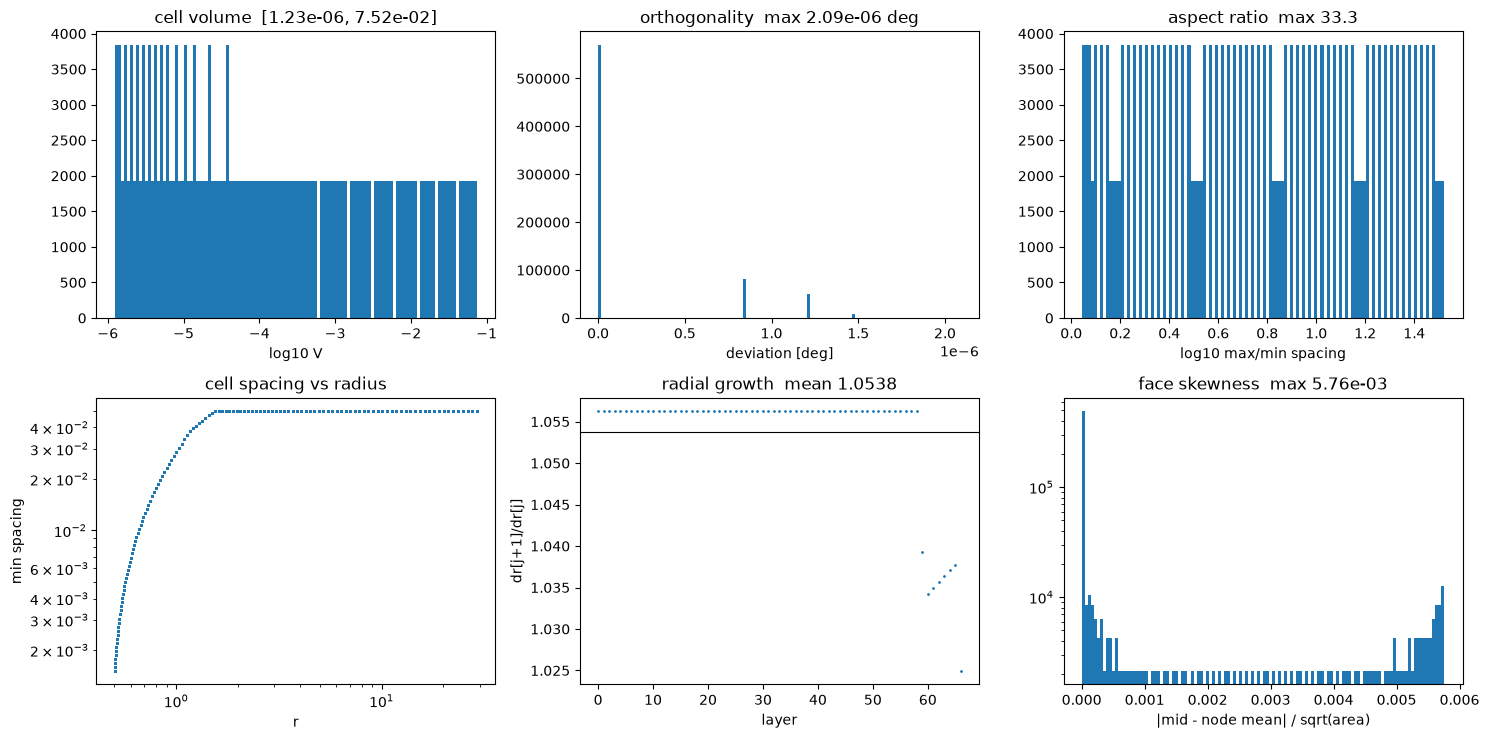

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))

ax[0, 0].hist(np.log10(VOL), bins=120)
ax[0, 0].set_title(f'cell volume  [{VOL.min():.2e}, {VOL.max():.2e}]')
ax[0, 0].set_xlabel('log10 V')

ax[0, 1].hist(orth, bins=120)
ax[0, 1].set_title(f'orthogonality  max {orth.max():.2e} deg')
ax[0, 1].set_xlabel('deviation [deg]')

ax[0, 2].hist(np.log10(aspect), bins=120)
ax[0, 2].set_title(f'aspect ratio  max {aspect.max():.1f}')
ax[0, 2].set_xlabel('log10 max/min spacing')

ax[1, 0].loglog(np.sort(rc), np.sort(spacing), '.', ms=1)
ax[1, 0].set_title('cell spacing vs radius')
ax[1, 0].set_xlabel('r')
ax[1, 0].set_ylabel('min spacing')

ax[1, 1].plot(np.arange(growth.size), growth, '.', ms=2)
ax[1, 1].axhline(growth.mean(), color='k', lw=0.8)
ax[1, 1].set_title(f'radial growth  mean {growth.mean():.4f}')
ax[1, 1].set_xlabel('layer')
ax[1, 1].set_ylabel('dr[j+1]/dr[j]')

ax[1, 2].hist(skewness, bins=120, log=True)
ax[1, 2].set_title(f'face skewness  max {skewness.max():.2e}')
ax[1, 2].set_xlabel('|mid - node mean| / sqrt(area)')

fig.tight_layout()
plt.show()


## 6. 结论

In [16]:
summary = {
    '合法性检查全部通过': all(legal.values()),
    '几何量检查全部通过': all(geom.values()),
    '体积全为正': bool(np.all(VOL > 0)),
    '边界闭合 (体积误差 < 1e-9)': abs(VOL.sum() - exact) / exact < 1e-9,
    '正交性偏差 < 10 deg': bool(orth.max() < 10.0),
    '径向增长比 < 1.2': bool(growth.max() < 1.2),
    '展向层数一致': span_uniform,
}
for k, val in summary.items():
    print(f'{"PASS" if val else "FAIL"}  {k}')
print()
print('ALL PASS' if all(summary.values()) else 'HAS FAILURE')


PASS  合法性检查全部通过
PASS  几何量检查全部通过
PASS  体积全为正
PASS  边界闭合 (体积误差 < 1e-9)
PASS  正交性偏差 < 10 deg
PASS  径向增长比 < 1.2
PASS  展向层数一致

ALL PASS
